# Advanced Data Augmentation with Keras

### Setup the environment

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator

### Load the CIFAR-10 Dataset

In [3]:
(X_train, y_train), (X_test,y_test) = tf.keras.datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 430s 3us/step


### Normalize the pixel values for augmentation

In [4]:
X_train = X_train.astype('float') / 255.0
X_test = X_test.astype('float') / 255.0

### Display a sample of the training images

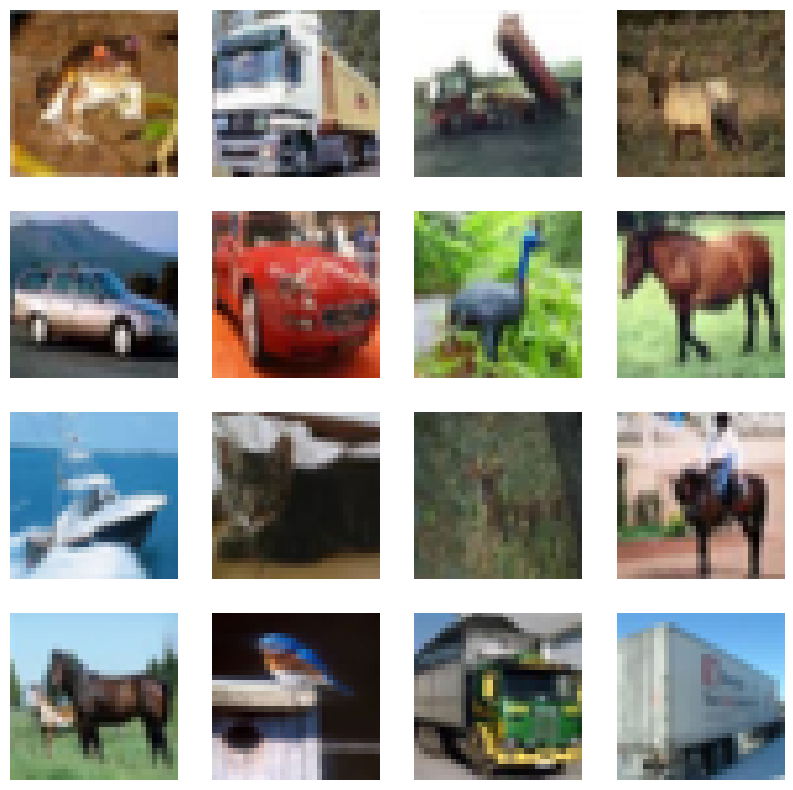

In [5]:
plt.figure(figsize=(10,10))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(X_train[i])
    plt.axis('off')

## Create sample.jpg for the Lab

In [6]:
from PIL import Image,ImageDraw

# Create a blank white image
image = Image.new('RGB',(224,224),color=(255,255,255))

# Draw a red square
draw = ImageDraw.Draw(image)
draw.rectangle([(50,50),(174,174)],fill=(255,0,0))

# Save the image
image.save('sample.jpg')

In [8]:
from tensorflow.keras.preprocessing.image import load_img , img_to_array

# Load a sample image
img_path = 'sample.jpg'
img = load_img(img_path)
x = img_to_array(img)
x = np.expand_dims(x,axis=0)

### Basic data augmentation

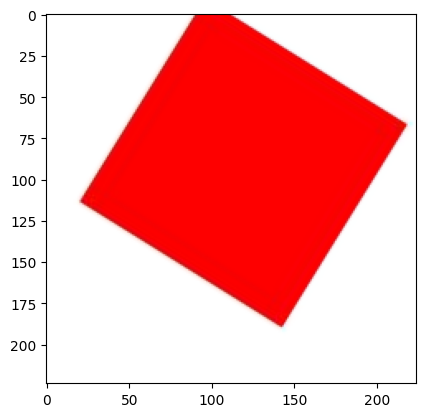

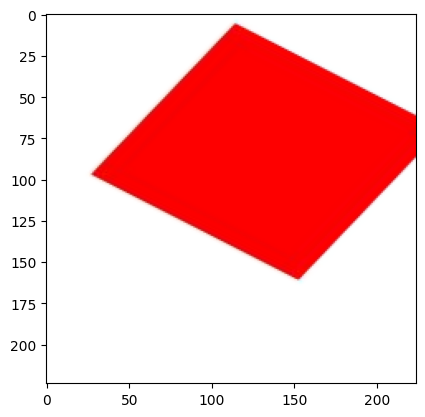

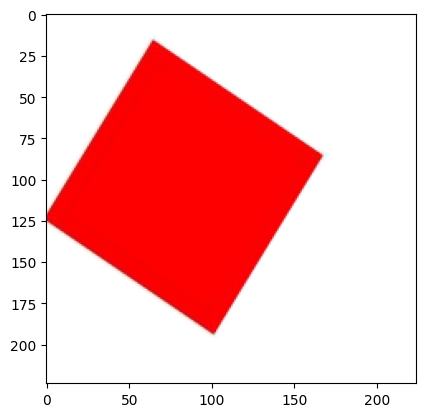

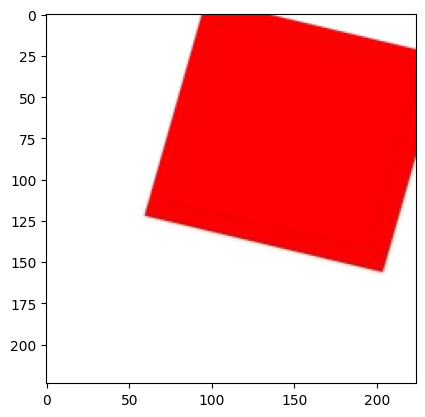

In [9]:
# Create an instance of ImageDataGenerator with basic augmentations
datagen = ImageDataGenerator(
    rotation_range = 40,
    width_shift_range = 0.2,
    height_shift_range = 0.2,
    shear_range = 0.2,
    zoom_range = 0.2,
    horizontal_flip = True,
    fill_mode = 'nearest'    
)

# Generate batches of augmented images
i=0
for batch in datagen.flow(x,batch_size=1):
    plt.figure(i)
    imgplot = plt.imshow(batch[0].astype('uint8'))
    i += 1
    if i % 4 == 0:
        break

### Feature-wise and sample-wise normalization

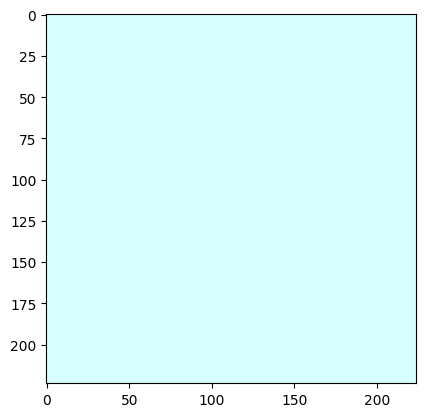

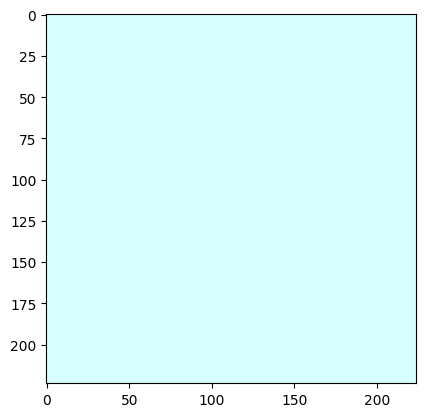

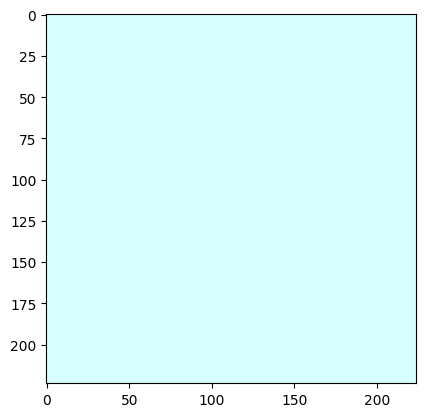

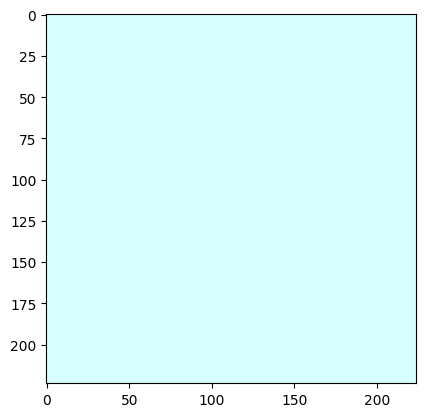

In [10]:
# Create an instance of ImageDataGenerator with normalization options
datagen = ImageDataGenerator(
    featurewise_center = True,
    featurewise_std_normalization = True,
    samplewise_center = True,
    samplewise_std_normalization = True
)

# Load the sample image again and fit the generator
datagen.fit(x)

# Generate batches of normalized image
i=0
for batch in datagen.flow(x,batch_size=1):
    plt.figure(i)
    imgplot = plt.imshow(batch[0].astype('uint8'))
    i += 1
    if i % 4 == 0:
        break

### Custom data augmentation function

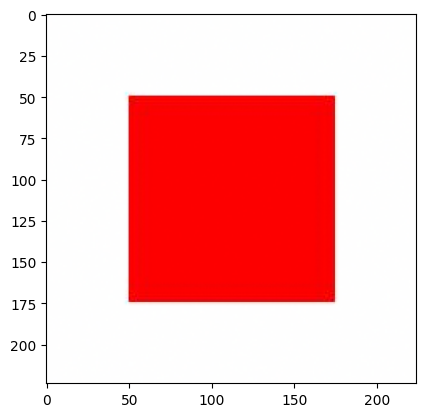

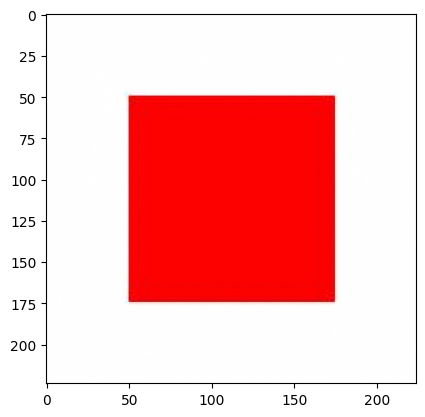

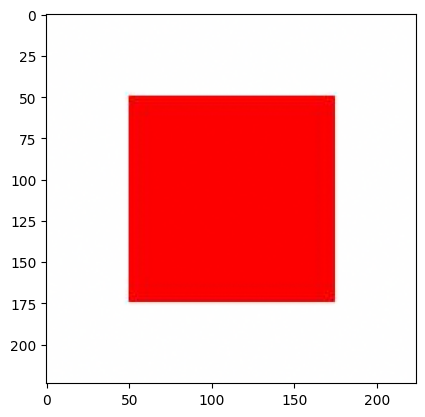

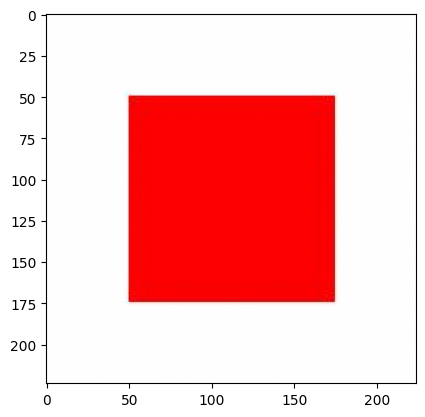

In [11]:
# Define a custom data augmentation function
def add_random_noise(image):
    noise = np.random.normal(0,0.1,image.shape)
    return image + noise

# Create an instance of ImageDataGenerator with custom augmentation
datagen = ImageDataGenerator(preprocessing_function=add_random_noise)

# Generate batch of aumented images with noise
i=0
for batch in datagen.flow(x,batch_size=1):
    plt.figure(i)
    imgplot = plt.imshow(batch[0].astype('uint8'))
    i += 1
    if i % 4 ==0:
        break

### Visualize augmented imges

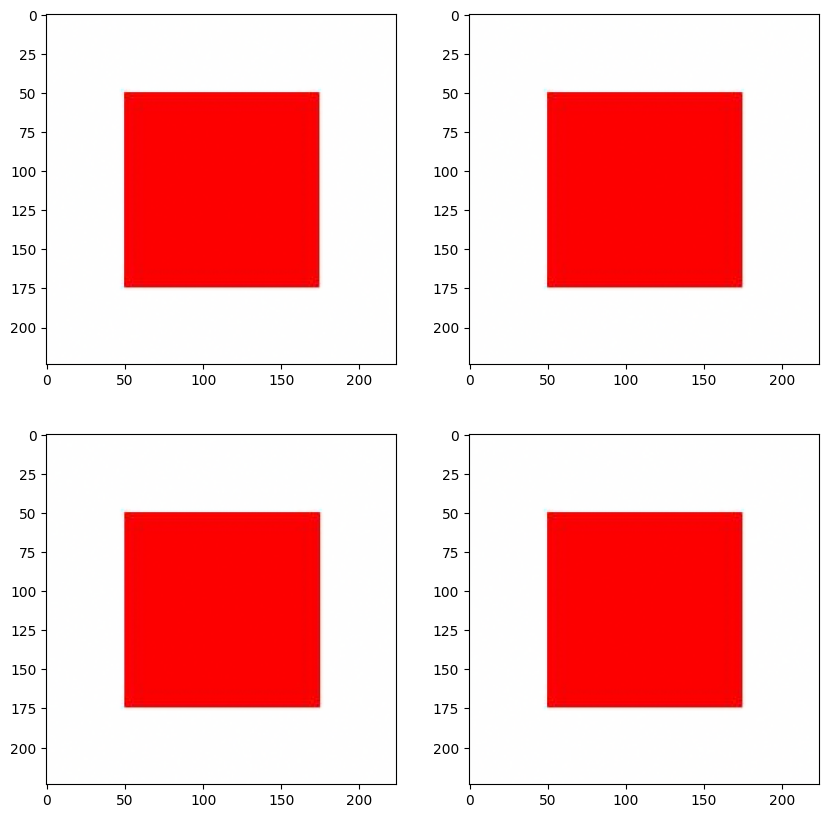

In [13]:
plt.figure(figsize=(10,10))
for i, batch in enumerate(datagen.flow(x,batch_size=1)):
    if i >= 4:
        break
    plt.subplot(2,2,i+1)
    plt.imshow(batch[0].astype('uint8'))